# 07 - Success and failure cases

**Owner:** Member 3
**Task:** Where does LightGCN's gain (or loss) come from? Recall@20 by item-popularity bucket and by user-degree group (cold/medium/heavy) on the biased and the unbiased test, for BPR-MF and LightGCN. Popularity of recommendations and coverage. Example users where LightGCN wins and where it fails. These results choose the improvement to implement.
**Inputs:** per-user recall from inference.evaluate, settings and models from notebook 06
**Outputs:** results/07_failure_cases.json, results/07_breakdown.png

After running: save the numbers to `results/`, append an entry to `LOG.md`, and write the matching report section.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import data
import models
import training
import inference
import analysis
from data import degrees
from utils.io import save_json, savefig
from utils.paths import DATA_DIR

SEED = 0  # single seed, like notebook 04's studies; notebook 06 confirms the headline over 3 seeds
DATASETS = ("kuairand", "kuairec")
LABELS = {"kuairand": "KuaiRand-Pure", "kuairec": "KuaiRec"}
RESULTS_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "results"))
os.makedirs(RESULTS_DIR, exist_ok=True)

## Experiments

## Models

Notebook 06's 3-seed models are not run yet, so both models are trained here with the settings notebooks 03 and
04 selected on validation Recall@20 (seed 0, batch 2048, max 100 epochs, early stopping on validation Recall@20,
the same protocol as the studies). Per-user recall, top-20 lists and metrics are cached under
`data/processed/07_cache_<dataset>_<model>.npz`; delete a cache to retrain. The MF grid ran on this machine and
the LightGCN grid on a GPU (the `.colab.json` files); both retrain here on CPU and reproduce the notebooks 03
and 04 numbers to four decimals, so the headline of notebook 06 can mix devices without changing conclusions.

In [2]:
SETTINGS = {
    "kuairand": dict(mf=dict(model="mf", dim=16, lr=1e-3, reg=1e-4),
                     lightgcn=dict(model="lightgcn", layers=3, dim=128, lr=1e-3, reg=1e-4)),
    "kuairec": dict(mf=dict(model="mf", dim=64, lr=1e-3, reg=1e-4),
                    lightgcn=dict(model="lightgcn", layers=3, dim=128, lr=1e-3, reg=1e-4)),
}


def load_ds(name, seed=SEED):
    try:
        return data.load_processed(name, seed=seed)
    except FileNotFoundError:
        return data.load(name, seed=seed)


def model_results(name, mkey):
    """Metrics, per-user recall and top-20 lists on both tests, from the cache or a fresh run."""
    path = os.path.join(DATA_DIR, "processed", f"07_cache_{name}_{mkey}.npz")
    if not os.path.exists(path):
        ds = load_ds(name)
        cfg = dict(SETTINGS[name][mkey], batch=2048, epochs=100, threads=8)
        out, rec_test, _, model = training.fit(cfg, ds, seed=SEED)
        rec_unb = inference.evaluate(model, ds, "test_unbiased", mask_splits=("train", "val", "test"))[1]
        arr = {s: np.full((ds["n_users"], 20), -1, dtype=np.int64) for s in ("test", "test_unbiased")}
        for s in arr:
            for u, v in analysis.topk(model, ds, s).items():
                arr[s][u] = v
        np.savez_compressed(path, rec_test=rec_test, rec_unb=rec_unb, tops_test=arr["test"],
                            tops_unb=arr["test_unbiased"],
                            metrics=json.dumps({k: out[k] for k in ("cfg", "val_recall", "best_epoch",
                                                                    "train_time", "test", "test_unbiased")}))
    z = np.load(path)
    return dict(metrics=json.loads(str(z["metrics"])),
                rec=dict(test=z["rec_test"], test_unbiased=z["rec_unb"]),
                tops=dict(test=z["tops_test"], test_unbiased=z["tops_unb"]))


R = {name: {m: model_results(name, m) for m in ("mf", "lightgcn")} for name in DATASETS}
rows = []
for name in DATASETS:
    for m, r in R[name].items():
        for split, label in (("test", "biased"), ("test_unbiased", "unbiased")):
            met = r["metrics"][split]
            rows.append(dict(dataset=name, model=m, test=label, recall=round(met["recall"], 4),
                             ndcg=round(met["ndcg"], 4), coverage=round(met["coverage"], 4),
                             popularity=round(met["popularity"], 1),
                             val_recall=round(r["metrics"]["val_recall"], 4),
                             train_time=round(r["metrics"]["train_time"])))
OVERVIEW = pd.DataFrame(rows)
OVERVIEW

,dataset,model,test,recall,ndcg,coverage,popularity,val_recall,train_time
0,kuairand,mf,biased,0.1666,0.1110,0.5312,1021.7,0.1632,237
1,kuairand,mf,unbiased,0.0058,0.0040,0.4878,1024.5,0.1632,237
2,kuairand,lightgcn,biased,0.2179,0.1461,0.4903,923.2,0.2109,5716
3,kuairand,lightgcn,unbiased,0.0063,0.0041,0.4602,922.5,0.2109,5716
4,kuairec,mf,biased,0.1051,0.1123,0.2034,681.7,0.1074,196
5,kuairec,mf,unbiased,0.1710,0.5556,0.1669,1006.3,0.1074,196
6,kuairec,lightgcn,biased,0.1255,0.1361,0.2695,641.9,0.1279,8155
7,kuairec,lightgcn,unbiased,0.1634,0.4896,0.4333,793.3,0.1279,8155


### Recall by item popularity

Items are split into five equal-count buckets by training degree (`analysis.item_groups`), so no test
information enters the grouping; Q1 is the coldest bucket, Q5 the most popular. Recall is the share of a
bucket's test positives that appear in the user's top 20 (a micro-average over positives; the headline
Recall@20 stays the macro-average over users). The buckets' test support differs hugely, and that skew is
itself part of the exposure-bias story, so the support is shown next to the recall.

In [3]:
DS = {name: load_ds(name) for name in DATASETS}
IG = {name: analysis.item_groups(DS[name]) for name in DATASETS}
UG = {name: analysis.user_groups(DS[name]) for name in DATASETS}


def tops_dict(name, m, split):
    return {u: v for u, v in enumerate(R[name][m]["tops"][split]) if v[0] >= 0}


ITEM_ROWS = []
for name in DATASETS:
    for m in ("mf", "lightgcn"):
        for split, label in (("test", "biased"), ("test_unbiased", "unbiased")):
            ITEM_ROWS += [dict(dataset=name, model=m, test=label, **r)
                          for r in analysis.recall_by_item_group(DS[name], split, tops_dict(name, m, split), IG[name])]

display(pd.DataFrame(ITEM_ROWS).pivot_table(index=["dataset", "test", "model"], columns="group", values="recall").round(4))
pd.DataFrame([r for r in ITEM_ROWS if r["model"] == "mf"]).pivot_table(
    index=["dataset", "test"], columns="group", values="positives")

group                            0       1       2       3       4
dataset  test     model                                           
kuairand biased   lightgcn  0.0010  0.0037  0.0082  0.0271  0.2499
                  mf        0.0000  0.0000  0.0015  0.0126  0.1986
         unbiased lightgcn  0.0000  0.0001  0.0002  0.0010  0.0185
                  mf        0.0000  0.0000  0.0001  0.0006  0.0196
kuairec  biased   lightgcn  0.0011  0.0035  0.0018  0.0027  0.0965
                  mf        0.0000  0.0006  0.0002  0.0007  0.0830
         unbiased lightgcn  0.0012  0.0000  0.0009  0.0037  0.0743
                  mf        0.0000  0.0000  0.0000  0.0004  0.0867

group                    0        1        2        3         4
dataset  test                                                  
kuairand biased     1024.0   2405.0   6009.0  17431.0  104567.0
         unbiased  30122.0  33160.0  36797.0  41893.0   52567.0
kuairec  biased      936.0   1720.0   6227.0  29236.0  131145.0
         unbiased    829.0    902.0   3463.0  39855.0  171678.0

### Recall by user degree

Users are split into cold / medium / heavy terciles of training interactions (`analysis.user_groups`). Recall
is the mean per-user recall inside each group; users with no targets in a split are skipped.

In [4]:
USER_ROWS = []
for name in DATASETS:
    for m in ("mf", "lightgcn"):
        for split, label in (("test", "biased"), ("test_unbiased", "unbiased")):
            USER_ROWS += [dict(dataset=name, model=m, test=label, **r)
                          for r in analysis.recall_by_user_group(R[name][m]["rec"][split], UG[name])]

display(pd.DataFrame(USER_ROWS).pivot_table(index=["dataset", "test", "model"], columns="group",
                                            values="recall").round(4))
pd.DataFrame(USER_ROWS).pivot_table(index=["dataset", "test"], columns="group", values="users")

group                            0       1       2
dataset  test     model                           
kuairand biased   lightgcn  0.2239  0.2354  0.1945
                  mf        0.1680  0.1742  0.1575
         unbiased lightgcn  0.0070  0.0067  0.0054
                  mf        0.0063  0.0060  0.0052
kuairec  biased   lightgcn  0.2195  0.1048  0.0522
                  mf        0.1816  0.0882  0.0454
         unbiased lightgcn  0.1699  0.0960  0.0264
                  mf        0.1776  0.1032  0.0429

group                   0       1       2
dataset  test                            
kuairand biased    8563.0  8563.0  8563.0
         unbiased  6609.0  7149.0  7757.0
kuairec  biased    2391.0  2391.0  2391.0
         unbiased  1284.0   123.0     1.0

### Where the gain comes from

LightGCN minus MF per bucket and per group, on each test: a positive delta means propagation helps there, a
negative one that it hurts. Comparing the deltas across the two tests is the point of the project: the same
models, scored on feedback the platform recommender did and did not choose.

In [5]:
def deltas(rows):
    piv = pd.DataFrame(rows).pivot_table(index=["dataset", "test", "group"], columns="model", values="recall")
    piv["delta"] = piv["lightgcn"] - piv["mf"]
    return piv.round(4)


display(deltas(ITEM_ROWS))
deltas(USER_ROWS)

model                    lightgcn      mf   delta
dataset  test     group                          
kuairand biased   0        0.0010  0.0000  0.0010
                  1        0.0037  0.0000  0.0037
                  2        0.0082  0.0015  0.0067
                  3        0.0271  0.0126  0.0145
                  4        0.2499  0.1986  0.0513
         unbiased 0        0.0000  0.0000 -0.0000
                  1        0.0001  0.0000  0.0000
                  2        0.0002  0.0001  0.0001
                  3        0.0010  0.0006  0.0004
                  4        0.0185  0.0196 -0.0011
kuairec  biased   0        0.0011  0.0000  0.0011
                  1        0.0035  0.0006  0.0029
                  2        0.0018  0.0002  0.0016
                  3        0.0027  0.0007  0.0020
                  4        0.0965  0.0830  0.0135
         unbiased 0        0.0012  0.0000  0.0012
                  1        0.0000  0.0000  0.0000
                  2        0.0009  0.0000  0.0009
                  3        0.0037  0.0004  0.0033
                  4        0.0743  0.0867 -0.0124

model                    lightgcn      mf   delta
dataset  test     group                          
kuairand biased   0        0.2239  0.1680  0.0558
                  1        0.2354  0.1742  0.0612
                  2        0.1945  0.1575  0.0370
         unbiased 0        0.0070  0.0063  0.0007
                  1        0.0067  0.0060  0.0008
                  2        0.0054  0.0052  0.0001
kuairec  biased   0        0.2195  0.1816  0.0378
                  1        0.1048  0.0882  0.0166
                  2        0.0522  0.0454  0.0068
         unbiased 0        0.1699  0.1776 -0.0076
                  1        0.0960  0.1032 -0.0072
                  2        0.0264  0.0429 -0.0165

### Example users

The three largest per-user recall gains and losses from MF to LightGCN on each test, with the user's training
degree. Recall@20 per user is `hits / targets`, so a gain of 1.0 means LightGCN recovers a user MF fully
missed.

In [6]:
EXAMPLES = {}
frames = []
for name in DATASETS:
    for split, label in (("test", "biased"), ("test_unbiased", "unbiased")):
        ex = analysis.wins_and_failures(R[name]["mf"]["rec"][split], R[name]["lightgcn"]["rec"][split],
                                        ds=DS[name], n=3)
        EXAMPLES[f"{name}|{label}"] = ex
        frames.append(pd.DataFrame(ex).assign(dataset=name, test=label))
pd.concat(frames, ignore_index=True)

,user,kind,recall_a,recall_b,delta,train_degree,dataset,test
0,17566,win,0.000000,1.000000,1.000000,3,kuairand,biased
1,1540,win,0.000000,1.000000,1.000000,6,kuairand,biased
2,6556,win,0.000000,1.000000,1.000000,5,kuairand,biased
3,2507,failure,1.000000,0.000000,-1.000000,5,kuairand,biased
4,24798,failure,1.000000,0.000000,-1.000000,4,kuairand,biased
5,21086,failure,1.000000,0.000000,-1.000000,5,kuairand,biased
6,18809,win,0.000000,1.000000,1.000000,3,kuairand,unbiased
7,24499,win,0.000000,1.000000,1.000000,5,kuairand,unbiased
8,12984,win,0.000000,1.000000,1.000000,3,kuairand,unbiased
9,15345,failure,1.000000,0.000000,-1.000000,14,kuairand,unbiased


### Figure

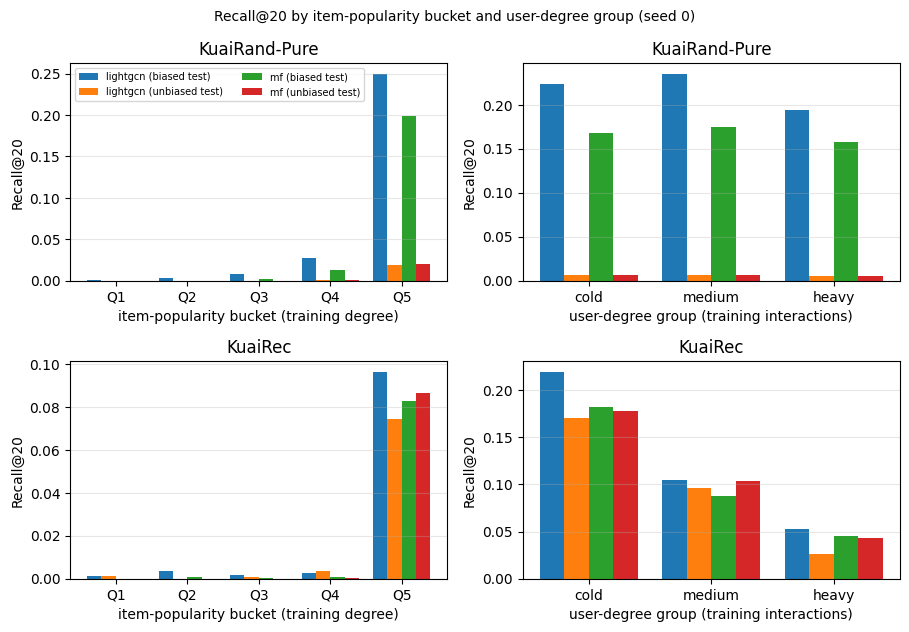

In [7]:
fig_rows = ([dict(dataset=LABELS[r["dataset"]], kind="item", group=r["group"], test=r["test"],
                  model=r["model"], recall=r["recall"]) for r in ITEM_ROWS]
          + [dict(dataset=LABELS[r["dataset"]], kind="user", group=r["group"], test=r["test"],
                  model=r["model"], recall=r["recall"]) for r in USER_ROWS])
fig = analysis.plot_breakdowns(fig_rows,
                               labels={"item": ["Q1", "Q2", "Q3", "Q4", "Q5"],
                                       "user": ["cold", "medium", "heavy"]},
                               title="Recall@20 by item-popularity bucket and user-degree group (seed 0)")
savefig(fig, "07_breakdown.png")
plt.show()

### What this chooses

Both models hit almost nothing outside the most-popular bucket: on the biased tests, recall in Q1-Q4 stays
below 0.03 everywhere, while Q5 reaches 0.20 (MF) and 0.25 (LightGCN) on KuaiRand-Pure and 0.08 / 0.10 on
KuaiRec. LightGCN's biased-test gain is therefore mostly more of the same: its delta grows monotonically with
popularity (+0.001 in Q1 to +0.051 in Q5 on KuaiRand-Pure; +0.001 to +0.014 on KuaiRec), and its
recommendations are only slightly less popular for it (mean training degree 923 vs MF's 1022 on KuaiRand-Pure).
On the unbiased tests the popular-bucket advantage disappears (KuaiRand-Pure: Q5 0.0185 vs MF's 0.0196,
overall +0.0005) or inverts (KuaiRec: Q5 0.074 vs MF's 0.087, overall -4%), even though LightGCN covers far
more items there (0.43 vs 0.17 coverage). By user degree the graph helps every group on KuaiRand-Pure
(+0.06 / +0.06 / +0.04 for cold / medium / heavy), but on KuaiRec it helps cold users most (+0.038) and heavy
users least (+0.007), and on KuaiRec's unbiased test it loses in every group. The extreme example users have
a single test positive (per-user recall is then 0 or 1), so their deltas of plus or minus 1.0 are the coin
flips of users the models barely know.

The failure pattern and the improvement it selects: the tail is unserved. On KuaiRand-Pure's unbiased test,
73% of the positives sit in Q1-Q4, where both models' recall is at most 0.001, and LightGCN amplifies the
popularity concentration rather than correcting it. Over-smoothing is not the binding constraint (recall
peaks at 3 layers and drops only slightly at 4, notebook 04), so this selects popularity-aware negative
sampling (oversample popular items as negatives, so the embeddings of tail items are not crowded out) as the
improvement to implement, to be reported as a separate row next to the main comparison.

In [8]:
out = dict(seed=SEED, settings=SETTINGS, overview=OVERVIEW.to_dict("records"),
           by_item=ITEM_ROWS, by_user=USER_ROWS,
           item_group_info={n: analysis.group_info(degrees(DS[n])[1], IG[n]) for n in DATASETS},
           user_group_info={n: analysis.group_info(degrees(DS[n])[0], UG[n]) for n in DATASETS},
           example_users=EXAMPLES)
save_json(out, "07_failure_cases.json")
print("saved results/07_failure_cases.json")

saved results/07_failure_cases.json
